# Tarefa 2: sinais vitais, escolhas e limites

Mário Cordeiro Júnior e André F. Maccarini

Queremos comparar Random Forest e MLP e mostrar onde elas podem falhar em casos delicados. Nossa preocupação principal é deixar uma vítima crítica sem reconhecimento. Também precisamos olhar os falsos alertas: ocupar uma equipe com alguém que não precisava daquela prioridade pode atrasar o socorro de outra vítima.

Nossa escolha é que o modelo sugira e a decisão final seja humana. Os três sinais não mostram risco ambiental, acesso ao local ou equipes disponíveis. Não vamos tratar uma boa porcentagem de acertos como prova de que o programa sabe decidir um resgate.

Este é o notebook da entrega e usa os mesmos dados, modelos e resultados do artigo. Para repetir os cálculos, execute as células em ordem. Precisamos de Python, NumPy e Matplotlib, além do Jupyter para abrir este arquivo. O código está inteiro neste notebook; não precisa de scripts separados. A busca de ajustes é executada novamente; os resultados já estão salvos nas saídas para permitir a leitura sem executar. Mantenha este arquivo junto da pasta `dados`.

## 1. O que decidimos

- Usar as técnicas pedidas na disciplina, mesmo quando o resultado não for bom.
- Começar pelas árvores, porque conseguimos seguir as perguntas até a resposta.
- Comparar gravidade e classe separadamente, como permitido no enunciado.
- Dar atenção aos críticos sem ignorar os falsos alertas.
- Comparar custos 1, 2, 5 e 10 como hipóteses nossas, não como custos médicos conhecidos.
- Limitar o crescimento das árvores e comparar ajustes fora do treino de cada rodada.
- Manter a incerteza quando faltam informações. A decisão final continua humana.

Os detalhes da execução são Gini nas árvores, três partes na validação cruzada, menor RMSE para gravidade e maior F1 macro para classe. Esses critérios têm limites, que vamos conferir nos resultados. Não são os únicos critérios possíveis.

In [1]:
from pathlib import Path
import ast, csv, html, io, json, sys
from contextlib import redirect_stdout
import numpy as np
from IPython.display import display, HTML, Image
BASE = Path.cwd()
assert (BASE/'dados/sinais_vitais_rotulados.csv').exists(), 'Abra este notebook na pasta tarefa-02-entrega.'
CLASSES = np.array([1, 2, 3, 4])
def tabela(cabecalho, linhas):
    def linha(valores, tag):
        return '<tr>' + ''.join(f'<{tag}>{html.escape(str(v))}</{tag}>' for v in valores) + '</tr>'
    display(HTML('<table>' + linha(cabecalho, 'th') + ''.join(linha(l, 'td') for l in linhas) + '</table>'))
def ler_json(nome):
    return json.loads((BASE/nome).read_text(encoding='utf8'))
def rodar_calculo(funcao, *argumentos):
    saida = io.StringIO()
    with redirect_stdout(saida):
        funcao(*argumentos)
    print(funcao.__name__, 'concluído. Os resultados aparecem nas tabelas abaixo.')
print('Python:', sys.version.split()[0], '| NumPy:', np.__version__)


Python: 3.11.9 | NumPy: 2.4.4


## 2. Quais dados entram

Usamos 1.500 registros fornecidos na atividade. O enunciado informa que os valores foram gerados aleatoriamente dentro de intervalos. Não são uma comprovação sobre pacientes reais.

Entram qPA, pulso e respiração. As pressões brutas ficam de fora, conforme o enunciado da atividade. qPA igual a zero representa qualidade máxima, não falta de informação. O ID só identifica a linha. Gravidade e classe são as respostas que queremos prever e não podem entrar como pistas para o modelo.

O arquivo chamado “sem rótulo” repete as entradas do rotulado. Por isso, não vamos usá-lo como teste novo. Não removemos extremos, preenchemos valores ausentes nem equilibramos artificialmente as classes.

In [2]:
dados = np.loadtxt(BASE / 'dados/sinais_vitais_rotulados.csv', delimiter=',')
sem_rotulo = np.loadtxt(BASE / 'dados/sinais_vitais_sem_rotulo.csv', delimiter=',')
assert dados.shape == (1500, 8) and np.isfinite(dados).all()
np.testing.assert_array_equal(dados[:, :6], sem_rotulo[:, :6])
ids = dados[:, 0].astype(int)
X = dados[:, 3:6]
gravidade = dados[:, 6]
classe = dados[:, 7].astype(int)
assert len(set(ids)) == len(ids)
tabela(['ID', 'qPA', 'Pulso', 'Respiração', 'Gravidade', 'Classe'],
       [[int(r[0]), *r[3:7], int(r[7])] for r in dados[:5]])
print('Total:', len(dados), '| As entradas do arquivo sem rótulo são as mesmas.')

ID,qPA,Pulso,Respiração,Gravidade,Classe
1,8.416754,75.921057,21.635259,40.0,2
2,8.72589,63.813564,19.718734,41.530427,2
3,0.0,197.210213,19.045471,52.730745,3
4,8.733333,143.636181,17.621141,34.679911,2
5,1.747626,82.636672,12.209535,69.375882,3


Total: 1500 | As entradas do arquivo sem rótulo são as mesmas.


## 3. Como separamos treino e avaliação

Mantivemos a divisão inicial: 900 registros para aprender e 600 para avaliar depois. O sorteio usa semente 42 para conseguirmos repeti-lo e mantém aproximadamente a proporção das classes.

Os 600 registros não entram no treino nem na busca de ajustes. Mas já tinham sido consultados no estudo anterior. Então, não vamos chamá-los de teste cego nem de avaliação final nunca vista.

Na busca, dividimos só os 900 registros em três partes. Cada rodada treina com duas e avalia a terceira. Assim, cada linha recebe uma previsão de um modelo que não treinou com ela.

In [3]:
HIPOTESE = {'fracao_aprender': .60, 'semente': 42, 'arvores': 9,
    'profundidade': 5, 'min_folha': 8, 'atributos_por_no': 2, 'max_cortes': 12,
    'neuronios': 8, 'passos_gradiente': 800, 'taxa': .05, 'l2': .001}
rng_divisao=np.random.default_rng(HIPOTESE['semente'])
aprender, observar = [], []
contagens=np.array([sum(classe==c) for c in CLASSES])
ideais=contagens*HIPOTESE['fracao_aprender']; por_classe=np.floor(ideais).astype(int)
faltam=int(round(len(classe)*HIPOTESE['fracao_aprender']))-int(por_classe.sum())
ordem=np.argsort(-(ideais-por_classe),kind='stable')
por_classe[ordem[:faltam]]+=1
for c,n in zip(CLASSES,por_classe):
    indices=rng_divisao.permutation(np.flatnonzero(classe==c))
    aprender.extend(indices[:n]); observar.extend(indices[n:])
idx_aprender=np.array(sorted(aprender)); idx_observar=np.array(sorted(observar))
assert set(idx_aprender).isdisjoint(idx_observar)
print('Aprender:',len(idx_aprender),'| observar:',len(idx_observar),'| não há teste final neste caderno.')
for c in CLASSES: print('Classe',c,':',sum(classe[idx_aprender]==c),'/',sum(classe[idx_observar]==c))

Aprender: 900 | observar: 600 | não há teste final neste caderno.
Classe 1 : 141 / 93
Classe 2 : 499 / 333
Classe 3 : 242 / 162
Classe 4 : 18 / 12


## 4. Como medimos os erros

RMSE mede o erro da gravidade na escala original: fazemos a média dos erros ao quadrado e tiramos a raiz. Quanto menor, melhor nesse critério.

Para a classe, usamos:

- Acurácia: proporção total de acertos.
- Recall dos críticos: quantos dos críticos foram reconhecidos.
- Precisão dos alertas críticos: quantos desses alertas estavam certos.
- F1: uma combinação de precisão e recall.
- F1 macro: média do F1 das quatro classes, com peso igual para cada uma.
- Matriz de confusão: mostra quais classes foram trocadas por quais.

Nenhuma medida basta sozinha. Podemos aumentar o recall e também aumentar os falsos alertas. Se não houver previsão de uma classe, o código registra sua precisão e seu F1 como zero.

As próximas células contêm as funções que usamos nesta análise.

In [4]:
def rmse(real, previsto):
    return float(np.sqrt(np.mean((np.asarray(real)-np.asarray(previsto))**2)))

def metricas_manuais(real, previsto):
    matriz=np.zeros((4,4),dtype=int)
    for verdadeiro,estimado in zip(real,previsto): matriz[int(verdadeiro)-1,int(estimado)-1]+=1
    acertos=np.diag(matriz).astype(float)
    suporte=matriz.sum(axis=1); previstos=matriz.sum(axis=0)
    precisao=np.divide(acertos,previstos,out=np.zeros(4),where=previstos>0)
    recall=np.divide(acertos,suporte,out=np.zeros(4),where=suporte>0)
    f1=np.divide(2*precisao*recall,precisao+recall,out=np.zeros(4),where=(precisao+recall)>0)
    return {'matriz':matriz,'precisao':precisao,'recall':recall,'f1':f1,
            'suporte':suporte,'acuracia':float(acertos.sum()/matriz.sum()),'f1_macro':float(f1.mean())}

## 5. Como a árvore faz as perguntas

Usamos árvores CART simplificadas. Cada pergunta compara um sinal com um valor de corte. Para classe, usamos Gini; para gravidade, usamos a variação dos valores em torno da média.

Queremos um corte que separe melhor os exemplos. Se os dois grupos mantêm a mesma proporção das classes, aquele corte não reduziu a mistura. Isso não prova que todas as outras perguntas sejam inúteis. Estudamos entropia e ganho de informação para entender essa ideia, mas este código usa Gini.

Sorteamos dois atributos por nó e examinamos até 12 cortes por atributo. Escolhemos o maior ganho positivo entre os candidatos. “Melhor” significa melhor nessa comparação, sem garantia de obter a melhor árvore inteira.

Cada folha precisa de pelo menos oito entradas. A árvore também para quando o nó fica puro, chega à profundidade máxima ou não encontra ganho positivo nos cortes permitidos. Não fazemos poda posterior. Limitar o crescimento procura evitar sobreajuste: aprender detalhes do treino que não ajudam em dados novos.

In [5]:
def impureza(alvos, tarefa):
    if tarefa=='regressao': return float(np.mean((alvos-alvos.mean())**2))
    frequencias=np.array([np.mean(alvos==c) for c in CLASSES])
    return float(1-np.sum(frequencias**2))

def ganho_do_corte(entradas, alvos, atributo, limiar, tarefa, min_folha=1):
    esquerda=entradas[:,atributo]<=limiar
    n_esq=int(esquerda.sum()); n_dir=len(alvos)-n_esq
    if min(n_esq,n_dir)<min_folha: return -np.inf
    depois=(n_esq*impureza(alvos[esquerda],tarefa)+n_dir*impureza(alvos[~esquerda],tarefa))/len(alvos)
    return impureza(alvos,tarefa)-depois

def limiares_candidatos(valores, max_cortes):
    unicos=np.unique(valores)
    meios=(unicos[:-1]+unicos[1:])/2
    if len(meios)>max_cortes:
        meios=meios[np.unique(np.linspace(0,len(meios)-1,max_cortes,dtype=int))]
    return meios

def construir_arvore(entradas, alvos, tarefa, max_profundidade=5, min_folha=8,
                     max_atributos=2, max_cortes=12, semente=42):
    rng=np.random.default_rng(semente)
    def crescer(a,b,profundidade):
        frequencias=np.array([np.mean(b==c) for c in CLASSES]) if tarefa=='classificacao' else None
        no={'n':len(b),'valor':float(b.mean()) if tarefa=='regressao' else int(CLASSES[np.argmax(frequencias)]),
            'probabilidades':frequencias,'cortes_examinados':0}
        if profundidade>=max_profundidade or len(b)<2*min_folha or impureza(b,tarefa)<1e-12:
            return no
        atributos=sorted(rng.choice(a.shape[1],min(max_atributos,a.shape[1]),replace=False))
        melhor=0.; escolha=None
        for atributo in atributos:
            for limiar in limiares_candidatos(a[:,atributo],max_cortes):
                no['cortes_examinados']+=1
                ganho=ganho_do_corte(a,b,atributo,limiar,tarefa,min_folha)
                if ganho>melhor+1e-12:
                    melhor=ganho; escolha=(int(atributo),float(limiar))
        if escolha is None: return no
        atributo,limiar=escolha; mask=a[:,atributo]<=limiar
        no.update(atributo=atributo,limiar=limiar,ganho=melhor,
                  esquerda=crescer(a[mask],b[mask],profundidade+1),
                  direita=crescer(a[~mask],b[~mask],profundidade+1))
        return no
    return crescer(np.asarray(entradas),np.asarray(alvos),0)

def folha_da_arvore(arvore, linha):
    no=arvore
    while 'atributo' in no:
        no=no['esquerda'] if linha[no['atributo']]<=no['limiar'] else no['direita']
    return no

def prever_arvore(arvore, entradas, tarefa):
    return np.array([folha_da_arvore(arvore,linha)['valor'] for linha in entradas])

## 6. Como juntamos as árvores

Cada árvore recebe um sorteio com reposição das linhas de treino. Uma linha pode aparecer mais de uma vez e outra pode ficar de fora. Isso e o sorteio dos atributos ajudam a formar árvores diferentes, mas não as tornam independentes.

Para a gravidade, tiramos a média das previsões. Para a classe, tiramos a média das proporções de classe das folhas alcançadas. A maior média define a classe antes de aplicar a regra de custo. Não é só contar o voto da classe vencedora de cada árvore.

In [6]:
def treinar_floresta(entradas, alvos, tarefa, n_arvores=9, max_profundidade=5,
                     min_folha=8, max_cortes=12, semente=42, max_atributos=2):
    rng=np.random.default_rng(semente); arvores=[]; amostras=[]
    for _ in range(n_arvores):
        indices=rng.integers(0,len(alvos),size=len(alvos))
        amostras.append(indices)
        arvores.append(construir_arvore(entradas[indices],alvos[indices],tarefa,
            max_profundidade,min_folha,min(max_atributos,entradas.shape[1]),max_cortes,int(rng.integers(2**31))))
    return {'arvores':arvores,'amostras':amostras,'tarefa':tarefa}

def probabilidades_floresta(floresta, entradas):
    por_arvore=np.array([[folha_da_arvore(a,linha)['probabilidades'] for linha in entradas]
                        for a in floresta['arvores']])
    return por_arvore.mean(axis=0)

def prever_floresta(floresta, entradas):
    if floresta['tarefa']=='classificacao':
        return CLASSES[np.argmax(probabilidades_floresta(floresta,entradas),axis=1)]
    return np.array([prever_arvore(a,entradas,'regressao') for a in floresta['arvores']]).mean(axis=0)

## 7. Como a rede recebe os valores

A MLP recebe os mesmos três sinais, mas padronizados: subtraímos a média e dividimos pelo desvio do treino. A gravidade também é padronizada no treino e volta à escala original na previsão. Na validação cruzada, cada rodada calcula essas escalas usando só sua parte de treino.

Usamos uma camada oculta com tanh. Para gravidade, há uma saída linear. Para classe, há quatro saídas, transformadas em probabilidades estimadas pela função softmax. Os pesos começam aleatórios, com semente 42, e os vieses começam em zero. As duas tarefas têm redes separadas, então a classe e a gravidade previstas podem discordar.

In [7]:
def ajustar_escala(entradas):
    media=np.mean(entradas,axis=0); desvio=np.std(entradas,axis=0)
    return {'media':media,'desvio':np.where(desvio==0,1.,desvio)}

def aplicar_escala(entradas, escala):
    return (entradas-escala['media'])/escala['desvio']

def inicializar_rede(n_entradas,n_ocultos,n_saidas,semente=42):
    rng=np.random.default_rng(semente)
    limite1=np.sqrt(6/(n_entradas+n_ocultos)); limite2=np.sqrt(6/(n_ocultos+n_saidas))
    return {'W1':rng.uniform(-limite1,limite1,(n_entradas,n_ocultos)),
            'b1':np.zeros((1,n_ocultos)),
            'W2':rng.uniform(-limite2,limite2,(n_ocultos,n_saidas)),
            'b2':np.zeros((1,n_saidas))}

def propagar_rede(p, entradas, tarefa):
    oculta=np.tanh(entradas@p['W1']+p['b1'])
    escores=oculta@p['W2']+p['b2']
    if tarefa=='regressao': return oculta,escores,escores,None
    deslocados=escores-escores.max(axis=1,keepdims=True)
    log_prob=deslocados-np.log(np.exp(deslocados).sum(axis=1,keepdims=True))
    return oculta,escores,np.exp(log_prob),log_prob

## 8. Como ajustamos os pesos

A retropropagação calcula como os pesos afetam a perda. A descida do gradiente usa esse cálculo e a taxa de aprendizado para atualizar os pesos.

Na gravidade, usamos metade do erro quadrático médio no alvo padronizado. Na classe, usamos entropia cruzada, que penaliza probabilidades baixas para a resposta correta. Nas duas tarefas, acrescentamos L2 com valor 0,001. Essa penalização desestimula pesos grandes, mas não garante bom resultado em dados novos.

Fazemos 800 atualizações usando todo o treino em cada uma. Esse limite mantém a execução pequena; não prova que chegamos à melhor solução ou que a rede parou de melhorar. Um resultado ruim aqui não significa que toda MLP seja ruim.

In [8]:
def perda_e_gradientes(p, entradas, alvos, tarefa, l2=.001):
    h,escores,saida,logp=propagar_rede(p,entradas,tarefa)
    n=len(entradas)
    if tarefa=='regressao':
        erro=saida-np.asarray(alvos).reshape(-1,1)
        perda=float(np.sum(erro**2)/(2*n)); delta=erro/n
    else:
        indices=np.asarray(alvos,dtype=int)-1
        perda=float(-np.mean(logp[np.arange(n),indices]))
        delta=saida.copy(); delta[np.arange(n),indices]-=1; delta/=n
    perda+=float(l2/2*(np.sum(p['W1']**2)+np.sum(p['W2']**2)))
    erro_oculto=(delta@p['W2'].T)*(1-h*h)
    grad={'W2':h.T@delta+l2*p['W2'],'b2':delta.sum(axis=0,keepdims=True),
          'W1':entradas.T@erro_oculto+l2*p['W1'],'b1':erro_oculto.sum(axis=0,keepdims=True)}
    return perda,grad

def treinar_rede(entradas,alvos,tarefa,n_ocultos=8,passos=800,taxa=.05,l2=.001,semente=42):
    if not np.isfinite(taxa) or taxa<0: raise ValueError('Taxa deve ser finita e não negativa.')
    p=inicializar_rede(entradas.shape[1],n_ocultos,1 if tarefa=='regressao' else 4,semente)
    historico=[]; normas=[]
    for _ in range(passos):
        perda,grad=perda_e_gradientes(p,entradas,alvos,tarefa,l2)
        if not np.isfinite(perda): raise ValueError('Perda não finita: reveja taxa, escala e dados.')
        historico.append(perda)
        normas.append(float(np.sqrt(sum(np.sum(v*v) for v in grad.values()))))
        for chave in p: p[chave]-=taxa*grad[chave]
    historico.append(perda_e_gradientes(p,entradas,alvos,tarefa,l2)[0])
    return {'parametros':p,'historico':np.array(historico),'normas':np.array(normas),'tarefa':tarefa}

def prever_rede(rede,entradas):
    saida=propagar_rede(rede['parametros'],entradas,rede['tarefa'])[2]
    return saida[:,0] if rede['tarefa']=='regressao' else CLASSES[np.argmax(saida,axis=1)]

## 9. Primeiro, a configuração inicial

Começamos com nove árvores, profundidade máxima cinco e pelo menos oito entradas por folha. Na MLP, começamos com oito neurônios ocultos, taxa 0,05 e 800 passos.

Mantemos essa versão para comparar com o que a busca escolheu depois. Também usamos uma referência simples: prever sempre a média da gravidade e a classe mais frequente do treino. A função abaixo treina, avalia e salva as previsões dessa versão.

In [9]:
def decidir_por_custo(probabilidades,custo_perder_critico=1):
    custo=np.ones((4,4))-np.eye(4)
    custo[0,1:]=custo_perder_critico
    esperado=probabilidades@custo
    return CLASSES[np.argmin(esperado,axis=1)]

def executar_analise(selecionados=False):
    from pathlib import Path
    import csv
    import hashlib
    import json
    import platform
    import sys
    import numpy as np
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    FINAL = selecionados
    OUT = BASE / ('dados/resultados_finais' if FINAL else 'dados/resultados')
    OUT.mkdir(exist_ok=True)
    dados = np.loadtxt(BASE/'dados/sinais_vitais_rotulados.csv', delimiter=',')
    sem_rotulo = np.loadtxt(BASE/'dados/sinais_vitais_sem_rotulo.csv', delimiter=',')
    assert dados.shape == (1500,8) and np.isfinite(dados).all()
    np.testing.assert_array_equal(dados[:,:6], sem_rotulo[:,:6])
    ids=dados[:,0].astype(int)
    assert len(np.unique(ids)) == len(ids)
    X,gravidade,classe=dados[:,3:6],dados[:,6],dados[:,7].astype(int)
    assert len(idx_aprender)==900 and len(idx_observar)==600
    assert set(idx_aprender).isdisjoint(idx_observar)
    opcoes={'n_arvores':HIPOTESE['arvores'], 'max_profundidade':HIPOTESE['profundidade'],
     'min_folha':HIPOTESE['min_folha'],'max_cortes':HIPOTESE['max_cortes'],
     'semente':HIPOTESE['semente'],'max_atributos':HIPOTESE['atributos_por_no']}
    escolhidas=json.loads((BASE/'dados/resultados/busca_configuracoes.json').read_text(encoding='utf8'))['escolhidas'] if FINAL else None
    opcoes_reg=escolhidas['Floresta_regressao']['config'] if FINAL else opcoes
    opcoes_clf=escolhidas['Floresta_classificacao']['config'] if FINAL else opcoes
    forest_reg=treinar_floresta(X[idx_aprender],gravidade[idx_aprender],'regressao',**opcoes_reg)
    forest_clf=treinar_floresta(X[idx_aprender],classe[idx_aprender],'classificacao',**opcoes_clf)
    escala_X=ajustar_escala(X[idx_aprender])
    escala_g=ajustar_escala(gravidade[idx_aprender])
    Xa=aplicar_escala(X[idx_aprender],escala_X)
    ga=aplicar_escala(gravidade[idx_aprender],escala_g)
    opcoes_rede={'n_ocultos':HIPOTESE['neuronios'],'passos':HIPOTESE['passos_gradiente'],
     'taxa':HIPOTESE['taxa'],'l2':HIPOTESE['l2'],'semente':HIPOTESE['semente']}
    rede_opcoes_reg=escolhidas['MLP_regressao']['config'] if FINAL else opcoes_rede
    rede_opcoes_clf=escolhidas['MLP_classificacao']['config'] if FINAL else opcoes_rede
    rede_reg=treinar_rede(Xa,ga,'regressao',**rede_opcoes_reg)
    rede_clf=treinar_rede(Xa,classe[idx_aprender],'classificacao',**rede_opcoes_clf)
    diagnosticos=[]
    confusoes={}
    por_classe=[]
    cenarios=[]
    previsoes=[]
    probs_observar={}
    for fase,indices in [('aprender',idx_aprender),('observar',idx_observar)]:
     for modelo in ['Floresta','MLP','Referencia']:
      if modelo=='Floresta':
       predg=prever_floresta(forest_reg,X[indices]);probs=probabilidades_floresta(forest_clf,X[indices]);predc=CLASSES[np.argmax(probs,axis=1)]
      elif modelo=='MLP':
       entrada=aplicar_escala(X[indices],escala_X)
       predg=prever_rede(rede_reg,entrada)*escala_g['desvio']+escala_g['media']
       probs=propagar_rede(rede_clf['parametros'],entrada,'classificacao')[2];predc=CLASSES[np.argmax(probs,axis=1)]
      else:
       predg=np.full(len(indices),gravidade[idx_aprender].mean())
       predc=np.full(len(indices),np.bincount(classe[idx_aprender]).argmax())
      metrics=metricas_manuais(classe[indices],predc)
      diagnosticos.append({'fase':fase,'modelo':modelo,'rmse':rmse(gravidade[indices],predg),'mae':float(np.mean(abs(gravidade[indices]-predg))),
       'acuracia':metrics['acuracia'],'f1_macro':metrics['f1_macro']})
      for c in range(4):por_classe.append({'fase':fase,'modelo':modelo,'classe':c+1,'suporte':int(metrics['suporte'][c]),
       'precisao':float(metrics['precisao'][c]),'recall':float(metrics['recall'][c]),'f1':float(metrics['f1'][c])})
      if fase=='observar':
       confusoes[modelo]=metrics['matriz']
       if modelo=='Referencia':continue
       probs_observar[modelo]=probs
       for k,row in enumerate(indices):previsoes.append({'id':int(ids[row]),'modelo':modelo,'gravidade_real':float(gravidade[row]),'gravidade_prevista':float(predg[k]),'classe_real':int(classe[row]),'classe_prevista':int(predc[k]),**{f'p{j+1}':float(probs[k,j]) for j in range(4)}})
       for custo in [1,2,5,10]:
        C=np.ones((4,4))-np.eye(4);C[0,1:]=custo
        decisao=decidir_por_custo(probs,custo);m=metricas_manuais(classe[indices],decisao)
        fn=int(sum((classe[indices]==1)&(decisao!=1)));fp=int(sum((classe[indices]!=1)&(decisao==1)))
        erros=int(sum(classe[indices]!=decisao));total=float(C[classe[indices]-1,decisao-1].sum())
        assert total==custo*fn+(erros-fn)
        if custo==1:np.testing.assert_array_equal(decisao,predc)
        cenarios.append({'modelo':modelo,'custo_perder_critico':custo,'fn_criticos':fn,'fp_criticos':fp,
         'recall_criticos':float(m['recall'][0]),'precisao_criticos':float(m['precisao'][0]),
         'acuracia':m['acuracia'],'f1_macro':m['f1_macro'],'erros_totais':erros,
         'custo_total_observado':total,'custo_medio_observado':total/len(indices),
         'custo_total_regra_maior_probabilidade':float(C[classe[indices]-1,predc-1].sum()),
         'custo_medio_estimado':float((probs@C).min(axis=1).mean()),'matriz':m['matriz']})
        confusoes[f'{modelo}_custo_{custo}']=m['matriz']
    for p in probs_observar.values():
     np.testing.assert_allclose(p.sum(axis=1),1,atol=1e-12)
     assert np.isfinite(p).all() and (p>=0).all()
    np.testing.assert_allclose(impureza(np.array([1,1,2,2]),'classificacao'),.5)
    np.testing.assert_array_equal(decidir_por_custo(np.array([[.4,.6,0,0]]),5),[1])
    grad_errors={}
    for tarefa,y in [('regressao',np.array([-.2,.3,.1])),('classificacao',np.array([1,2,4]))]:
     x=np.array([[.2,-.4],[.5,.1],[-.3,.7]]); p=inicializar_rede(2,3,1 if tarefa=='regressao' else 4,17)
     _,g=perda_e_gradientes(p,x,y,tarefa);errs=[];eps=1e-5
     for key,values in p.items():
      for ix in np.ndindex(values.shape):
       old=values[ix];values[ix]=old+eps;plus=perda_e_gradientes(p,x,y,tarefa)[0]
       values[ix]=old-eps;minus=perda_e_gradientes(p,x,y,tarefa)[0];values[ix]=old
       errs.append(abs((plus-minus)/(2*eps)-g[key][ix]))
     grad_errors[tarefa]=float(max(errs));assert max(errs)<1e-7
    def serial(v):
     if isinstance(v,np.ndarray):return v.tolist()
     if isinstance(v,np.generic):return v.item()
     raise TypeError(type(v).__name__)
    report={'configuracao_inicial':HIPOTESE,'configuracoes_efetivas':{'floresta_reg':opcoes_reg,'floresta_clf':opcoes_clf,'rede_reg':rede_opcoes_reg,'rede_clf':rede_opcoes_clf},'selecao_por_validacao':FINAL,'particao':{'aprender':ids[idx_aprender],'observar':ids[idx_observar]},
     'contagens':{str(c):[int(sum(classe==c)),int(sum(classe[idx_aprender]==c)),int(sum(classe[idx_observar]==c))] for c in CLASSES},
     'diagnosticos':diagnosticos,'por_classe':por_classe,'confusoes':confusoes,'cenarios':cenarios,
     'gradientes_erro_maximo':grad_errors,'sem_rotulo_mesmas_entradas':True,
     'diferenca_arredondamento_gravidade':float(np.max(abs(gravidade-sem_rotulo[:,6]))),
     'duplicatas_entradas':int(len(X)-len(np.unique(X,axis=0))),
     'perdas_mlp':{nome:{'inicial':float(rede['historico'][0]),'final':float(rede['historico'][-1]),'norma_ultimo_gradiente':float(rede['normas'][-1])} for nome,rede in [('regressao',rede_reg),('classificacao',rede_clf)]},
     'ambiente':{'python':platform.python_version(),'numpy':np.__version__,'matplotlib':matplotlib.__version__},
     'hashes':{p.name:hashlib.sha256(p.read_bytes()).hexdigest() for p in [BASE/'dados/sinais_vitais_rotulados.csv']}}
    (OUT/'resultados.json').write_text(json.dumps(report,default=serial,ensure_ascii=False,indent=2),encoding='utf8')
    modelo_salvo={'escala_X':escala_X,'escala_g':escala_g,
     'floresta_reg':{'arvores':forest_reg['arvores'],'tarefa':'regressao'},
     'floresta_clf':{'arvores':forest_clf['arvores'],'tarefa':'classificacao'},
     'rede_reg':{'parametros':rede_reg['parametros'],'tarefa':'regressao'},
     'rede_clf':{'parametros':rede_clf['parametros'],'tarefa':'classificacao'}}
    (OUT/'modelos_treinados.json').write_text(json.dumps(modelo_salvo,default=serial,ensure_ascii=False),encoding='utf8')
    for name,rows in [('metricas',diagnosticos),('metricas_por_classe',por_classe),('cenarios_custo',[{k:v for k,v in r.items() if k!='matriz'} for r in cenarios]),('previsoes_observacao',previsoes)]:
     with (OUT/f'{name}.csv').open('w',newline='',encoding='utf8') as f:
      w=csv.DictWriter(f,fieldnames=list(rows[0]));w.writeheader();w.writerows(rows)
    plt.rcParams.update({'font.size':10,'figure.dpi':160,'axes.spines.top':False,'axes.spines.right':False})
    fig,axes=plt.subplots(1,2,figsize=(8.4,3.5))
    for ax,nome in zip(axes,['Floresta','MLP']):
     cm=confusoes[nome];ax.imshow(cm,cmap='Blues',vmin=0,vmax=333)
     for i in range(4):
      for j in range(4):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>170 else 'black')
     ax.set(xticks=range(4),xticklabels=[1,2,3,4],yticks=range(4),yticklabels=[1,2,3,4],xlabel='Classe prevista',ylabel='Classe fornecida',title=nome)
    fig.tight_layout()
    fig.savefig(OUT/'matrizes_confusao.png',bbox_inches='tight')
    plt.close(fig)
    fig,ax=plt.subplots(figsize=(7.5,3.4))
    for modelo,marker in [('Floresta','o'),('MLP','s')]:
     r=[x for x in cenarios if x['modelo']==modelo]
     ax.plot([v['fp_criticos'] for v in r],[v['fn_criticos'] for v in r],marker=marker,label=modelo)
     for v in r:ax.annotate('c='+str(v['custo_perder_critico']),(v['fp_criticos'],v['fn_criticos']),xytext=(5,5),textcoords='offset points')
    ax.set(xlabel='Falsos alertas críticos (FP)',ylabel='Críticos não reconhecidos (FN)')
    ax.legend()
    fig.tight_layout()
    fig.savefig(OUT/'troca_erros.png',bbox_inches='tight')
    plt.close(fig)
    print(json.dumps({'diagnosticos':diagnosticos,'cenarios':[{k:v for k,v in c.items() if k not in ['matriz']} for c in cenarios],'gradientes':grad_errors},ensure_ascii=False,indent=2))

rodar_calculo(executar_analise)
inicial = ler_json('dados/resultados/resultados.json')

executar_analise concluído. Os resultados aparecem nas tabelas abaixo.


## 10. A busca de ajustes

Os materiais da disciplina apresentam hiperparâmetros e recomendam validação cruzada. Automatizamos uma comparação pequena desses ajustes:

| Técnica | O que variamos | O que mantivemos |
|---|---|---|
| Floresta | Profundidade 3, 5 ou 7; 9 ou 25 árvores | Mínimo de 8 entradas por folha; 2 atributos por nó; até 12 cortes |
| MLP | 4, 8 ou 12 neurônios; taxa 0,01 ou 0,05 | Uma camada oculta; tanh; 800 passos; L2 igual a 0,001 |

São seis configurações por técnica e por tarefa. Com três rodadas, temos 72 ajustes. Na gravidade, escolhemos o menor RMSE. Na classe, o maior F1 macro. Juntamos as 900 previsões feitas fora do treino de cada rodada para calcular esses critérios.

Escolhemos F1 macro para dar peso igual às classes, mas isso não dá um peso extra aos críticos. Vamos analisar essa limitação depois. Em empate, fica a primeira configuração da ordem registrada, que começa pelos menores valores. O código completo dessa comparação aparece na próxima célula.

Não mudamos os valores da busca depois de olhar os 600 casos. Essa busca não cobre todas as possibilidades e não garante o melhor modelo possível.

In [10]:
def buscar_configuracoes():
    from pathlib import Path
    import csv,itertools,json
    import numpy as np
    dados=np.loadtxt(BASE/'dados/sinais_vitais_rotulados.csv',delimiter=',')
    ids=dados[:,0].astype(int)
    classe=dados[:,7].astype(int)
    X=dados[idx_aprender,3:6]
    g=dados[idx_aprender,6]
    y=classe[idx_aprender]
    rng=np.random.default_rng(42)
    folds=[[] for _ in range(3)]
    for c in CLASSES:
     for k,part in enumerate(np.array_split(rng.permutation(np.flatnonzero(y==c)),3)):folds[k].extend(part.tolist())
    folds=[np.array(sorted(v)) for v in folds]
    assert sorted(np.concatenate(folds).tolist())==list(range(900))
    forests=[{'n_arvores':n,'max_profundidade':p,'min_folha':8,'max_cortes':12,'max_atributos':2,'semente':42} for p,n in itertools.product([3,5,7],[9,25])]
    redes=[{'n_ocultos':h,'passos':800,'taxa':lr,'l2':.001,'semente':42} for h,lr in itertools.product([4,8,12],[.01,.05])]
    resultados=[]
    selected={}
    fold_results=[]
    for familia,configs in [('Floresta',forests),('MLP',redes)]:
     for tarefa in ['regressao','classificacao']:
      candidatos=[]
      for cid,config in enumerate(configs):
       pred_oof=np.empty(900);reg_errors=[]
       for k,val in enumerate(folds):
        train=np.setdiff1d(np.arange(900),val)
        assert set(ids[idx_aprender[train]]).isdisjoint(ids[idx_observar])
        if familia=='Floresta':
         model=treinar_floresta(X[train],g[train] if tarefa=='regressao' else y[train],tarefa,**config)
         pred=prever_floresta(model,X[val])
        else:
         escala=ajustar_escala(X[train]);a=aplicar_escala(X[train],escala);v=aplicar_escala(X[val],escala)
         if tarefa=='regressao':
          escala_g=ajustar_escala(g[train]);alvo=aplicar_escala(g[train],escala_g)
         else:alvo=y[train]
         model=treinar_rede(a,alvo,tarefa,**config);pred=prever_rede(model,v)
         if tarefa=='regressao':pred=pred*escala_g['desvio']+escala_g['media']
        pred_oof[val]=pred
        value=rmse(g[val],pred) if tarefa=='regressao' else metricas_manuais(y[val],pred)['f1_macro']
        reg_errors.append(value);fold_results.append({'familia':familia,'tarefa':tarefa,'config_id':cid,'fold':k+1,'n_treino':len(train),'n_validacao':len(val),'medida':float(value)})
       if tarefa=='regressao':metrics={'rmse_oof':rmse(g,pred_oof)};score=metrics['rmse_oof']
       else:
        m=metricas_manuais(y,pred_oof.astype(int));score=-m['f1_macro']
        metrics={'f1_macro_oof':m['f1_macro'],'acuracia_oof':m['acuracia'],'recall_criticos_oof':float(m['recall'][0]),'precisao_criticos_oof':float(m['precisao'][0])}
       record={'familia':familia,'tarefa':tarefa,'config_id':cid,'config':config,'medida_por_fold':reg_errors,**metrics}
       candidatos.append((score,cid,record));resultados.append(record)
       print(f'{familia} {tarefa} configuração {cid+1}/6: {metrics}',flush=True)
      chosen=min(candidatos,key=lambda v:(v[0],v[1]))[2]
      selected[f'{familia}_{tarefa}']=chosen
    out={'protocolo':'3 folds estratificados somente nas 900 linhas de aprendizado; previsoes fora do fold agregadas',
     'criterios':{'regressao':'menor RMSE nas 900 previsoes OOF','classificacao':'maior F1 macro nas 900 previsoes OOF','empate':'primeira configuracao na ordem declarada'},
     'configuracoes':resultados,'escolhidas':selected,'folds_ids':[ids[idx_aprender[v]].tolist() for v in folds],
     'indices_externos_proibidos_na_selecao':ids[idx_observar].tolist()}
    (BASE/'dados/resultados/busca_configuracoes.json').write_text(json.dumps(out,ensure_ascii=False,indent=2),encoding='utf8')
    with (BASE/'dados/resultados/medidas_folds.csv').open('w',encoding='utf8',newline='') as f:
     w=csv.DictWriter(f,fieldnames=list(fold_results[0]));w.writeheader();w.writerows(fold_results)
    print('Escolhidas:',json.dumps(selected,ensure_ascii=False,indent=2))

rodar_calculo(buscar_configuracoes)
busca = ler_json('dados/resultados/busca_configuracoes.json')
linhas = []
for item in busca['escolhidas'].values():
    c = item['config']
    ajustes = f"{c['n_arvores']} árvores, profundidade {c['max_profundidade']}" if item['familia'] == 'Floresta' else f"{c['n_ocultos']} neurônios, taxa {c['taxa']}"
    medida = f"RMSE {item['rmse_oof']:.3f}" if item['tarefa'] == 'regressao' else f"F1 macro {item['f1_macro_oof']:.3f}"
    linhas.append([item['familia'], item['tarefa'], ajustes, medida])
tabela(['Técnica', 'Tarefa', 'Configuração escolhida', 'Validação'], linhas)
assert len(busca['configuracoes']) * 3 == 72
print('72 ajustes internos. As 600 linhas ficaram fora da escolha.')

buscar_configuracoes concluído. Os resultados aparecem nas tabelas abaixo.


Técnica,Tarefa,Configuração escolhida,Validação
Floresta,regressao,"25 árvores, profundidade 7",RMSE 5.345
Floresta,classificacao,"9 árvores, profundidade 7",F1 macro 0.774
MLP,regressao,"8 neurônios, taxa 0.05",RMSE 8.399
MLP,classificacao,"8 neurônios, taxa 0.05",F1 macro 0.394


72 ajustes internos. As 600 linhas ficaram fora da escolha.


## 11. O que aconteceu depois da escolha

Treinamos as configurações escolhidas nas 900 linhas completas e avaliamos nas 600 reservadas. A floresta ficou com profundidade sete, 25 árvores para gravidade e nove para classe. A busca manteve oito neurônios e taxa 0,05 nas duas MLPs.

Vamos comparar treino e avaliação com custos iguais. Uma diferença entre esses resultados merece atenção, mas sozinha não prova sobreajuste.

In [11]:
rodar_calculo(executar_analise, True)
final = ler_json('dados/resultados_finais/resultados.json')
linhas = []
for versao, resultado in [('Inicial', inicial), ('Escolhida', final)]:
    for m in resultado['diagnosticos']:
        if m['modelo'] == 'Referencia':
            continue
        linhas.append([m['modelo'], versao, 'Treino' if m['fase'] == 'aprender' else 'Avaliação',
                       f"{m['rmse']:.3f}", f"{100*m['acuracia']:.2f}%", f"{m['f1_macro']:.3f}"])
m = next(m for m in final['diagnosticos'] if m['modelo'] == 'Referencia' and m['fase'] == 'observar')
linhas.append(['Referência', 'Constante', 'Avaliação', f"{m['rmse']:.3f}", f"{100*m['acuracia']:.2f}%", f"{m['f1_macro']:.3f}"])
tabela(['Modelo', 'Versão', 'Dados', 'RMSE', 'Acerto', 'F1 macro'], linhas)

executar_analise concluído. Os resultados aparecem nas tabelas abaixo.


Modelo,Versão,Dados,RMSE,Acerto,F1 macro
Floresta,Inicial,Treino,5.452,89.33%,0.671
MLP,Inicial,Treino,8.201,63.11%,0.389
Floresta,Inicial,Avaliação,6.461,85.83%,0.638
MLP,Inicial,Avaliação,8.521,63.67%,0.395
Floresta,Escolhida,Treino,3.638,93.00%,0.904
MLP,Escolhida,Treino,8.201,63.11%,0.389
Floresta,Escolhida,Avaliação,4.678,88.50%,0.754
MLP,Escolhida,Avaliação,8.521,63.67%,0.395
Referência,Constante,Avaliação,16.490,55.50%,0.178


Nos 600 registros, a floresta passou de RMSE 6,461 para 4,678 e de F1 macro 0,638 para 0,754. A acurácia passou de 85,83% para 88,50%. A MLP manteve RMSE 8,521, F1 macro 0,395 e acurácia de 63,67%.

Isso mostra melhora da floresta nesses critérios, mas ainda precisamos olhar os tipos de erro. Não vamos concluir só pela média.

## 12. Quais classes foram confundidas

Temos 93 críticos e só 12 estáveis na avaliação. Entre os estáveis, um acerto a mais muda o recall em cerca de 8,33 pontos percentuais. Por isso, uma porcentagem dessa classe precisa ser lida com cuidado.

Modelo,Classe,Casos,Precisão,Recall,F1
Floresta,1,93,97.10%,72.04%,0.827
Floresta,2,333,87.81%,95.20%,0.914
Floresta,3,162,86.23%,88.89%,0.875
Floresta,4,12,100.00%,25.00%,0.400
MLP,1,93,72.00%,19.35%,0.305
MLP,2,333,64.40%,85.29%,0.734
MLP,3,162,59.70%,49.38%,0.541
MLP,4,12,0.00%,0.00%,0.000


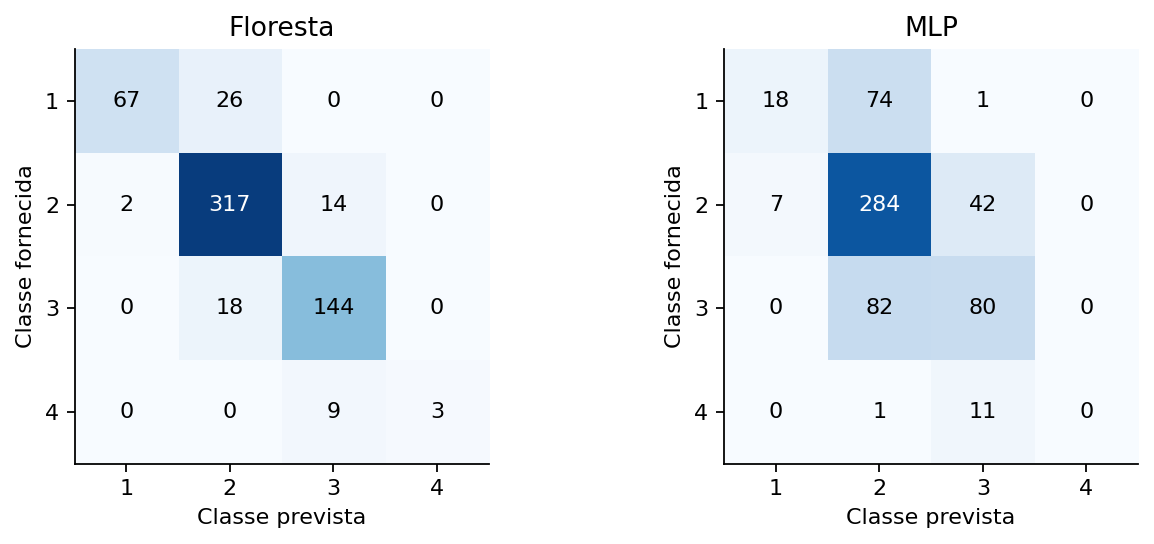

Floresta | Críticos não reconhecidos antes: 24 | Depois: 26
MLP | Críticos não reconhecidos antes: 75 | Depois: 75


In [12]:
linhas = [[m['modelo'], m['classe'], m['suporte'], f"{100*m['precisao']:.2f}%",
           f"{100*m['recall']:.2f}%", f"{m['f1']:.3f}"]
          for m in final['por_classe'] if m['fase'] == 'observar' and m['modelo'] != 'Referencia']
tabela(['Modelo', 'Classe', 'Casos', 'Precisão', 'Recall', 'F1'], linhas)
display(Image(filename=str(BASE / 'dados/resultados_finais/matrizes_confusao.png')))
for nome in ['Floresta', 'MLP']:
    cm = np.array(final['confusoes'][nome])
    cm_inicial = np.array(inicial['confusoes'][nome])
    print(nome, '| Críticos não reconhecidos antes:', cm_inicial[0].sum() - cm_inicial[0, 0],
          '| Depois:', cm[0].sum() - cm[0, 0])

A floresta reconheceu 67 dos 93 críticos e 3 dos 12 estáveis. A MLP reconheceu 18 críticos e nenhum estável. Na versão inicial, nenhuma das duas reconhecia os estáveis.

A floresta escolhida deixou de reconhecer 26 críticos, contra 24 antes. Então, aumentar o F1 macro não melhorou o reconhecimento dos críticos nesta avaliação. Essa é uma limitação da nossa regra de escolha: ela considera todas as classes com o mesmo peso, mas nossa preocupação com os críticos é maior.

Na figura, a diagonal mostra os acertos. Os outros números mostram para qual classe cada erro foi. Isso explica mais do que uma única porcentagem de acertos.

## 13. O que muda quando damos mais peso a um erro

Não sabemos o custo real de perder uma vítima crítica nem o de deslocar uma equipe para um falso alerta. Por isso, comparamos hipóteses.

Acertar custa zero. Prever outra classe para um crítico custa 1, 2, 5 ou 10, conforme o cenário. Os outros erros custam um. Para cada resposta possível, multiplicamos as probabilidades pelos custos e somamos. Escolhemos a resposta de menor custo esperado.

Mudar o custo muda só a decisão feita com as probabilidades. Não muda os pesos nem as árvores. Com custo 1, a regra equivale a escolher a classe mais provável. Em empate, fica a primeira classe.

Esses fatores são escolhas de comparação. Não representam valores médicos, dinheiro ou vidas perdidas.

In [13]:
def decidir_por_custo(probabilidades,custo_perder_critico=1):
    custo=np.ones((4,4))-np.eye(4)
    custo[0,1:]=custo_perder_critico
    esperado=probabilidades@custo
    return CLASSES[np.argmin(esperado,axis=1)]

Modelo,Custo de perder crítico,Críticos não reconhecidos,Falsos alertas,Recall dos críticos,Precisão dos alertas,Custo: regra de custo / maior probabilidade
Floresta,1,26,2,72.04%,97.10%,69 / 69
Floresta,2,17,9,81.72%,89.41%,84 / 95
Floresta,5,4,34,95.70%,72.36%,94 / 173
Floresta,10,1,76,98.92%,54.76%,125 / 303
MLP,1,75,7,19.35%,72.00%,218 / 218
MLP,2,48,32,48.39%,58.44%,264 / 293
MLP,5,25,138,73.12%,33.01%,381 / 518
MLP,10,18,267,80.65%,21.93%,523 / 893


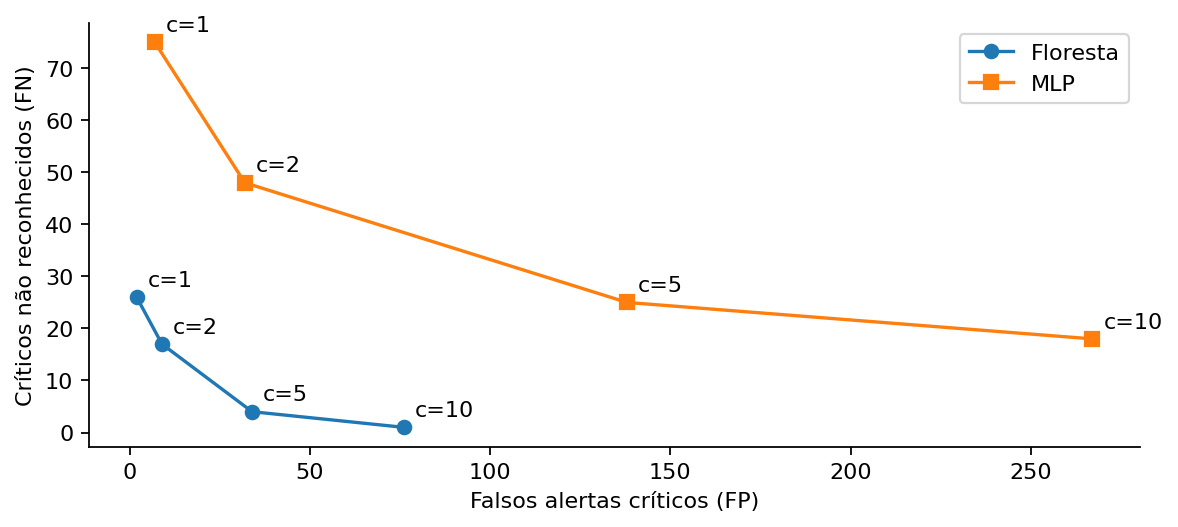

In [14]:
linhas = []
for c in final['cenarios']:
    linhas.append([c['modelo'], c['custo_perder_critico'], c['fn_criticos'], c['fp_criticos'],
                   f"{100*c['recall_criticos']:.2f}%", f"{100*c['precisao_criticos']:.2f}%",
                   f"{int(c['custo_total_observado'])} / {int(c['custo_total_regra_maior_probabilidade'])}"])
tabela(['Modelo', 'Custo de perder crítico', 'Críticos não reconhecidos', 'Falsos alertas',
        'Recall dos críticos', 'Precisão dos alertas', 'Custo: regra de custo / maior probabilidade'], linhas)
display(Image(filename=str(BASE / 'dados/resultados_finais/troca_erros.png')))

Na floresta, passar de custo 1 para 5 reduziu os críticos não reconhecidos de 26 para 4. Mas os falsos alertas passaram de 2 para 34. Com custo 10, ficou um crítico não reconhecido e 76 falsos alertas. Na MLP, custo 5 deixou 25 críticos sem reconhecimento e gerou 138 falsos alertas.

Por isso, olhar só o recall não basta. A floresta teve menor custo que a MLP nos quatro cenários, mas isso não prova que ela sempre seja melhor.

A última coluna compara duas regras usando o mesmo custo em cada linha. Não devemos comparar diretamente os totais de linhas com fatores diferentes. O custo observado usa a classe fornecida e pode ser diferente do esperado pelas probabilidades.

A matriz também deixa muita coisa de fora: trata os outros erros com o mesmo peso e não calcula o efeito de uma equipe ocupada sobre outra vítima. Não verificamos a calibração das probabilidades em outra população. Não escolhemos um fator definitivo para resgate real.

## 14. Conferências e arquivo de previsão

Conferimos a separação das linhas, os critérios da busca, os custos e o formato de saída. No treino também conferimos os gradientes por uma aproximação numérica em exemplos pequenos.

A função `executar` abaixo recebe um arquivo novo com quatro colunas, sem cabeçalho: ID, qPA, pulso e respiração. Ela produz dois arquivos com ID, gravidade e classe, um para cada técnica. Os exemplos desta conferência usam os 600 registros conhecidos; não são um teste cego novo.

Depois de executar as células anteriores, podemos usar `executar(BASE/'novos_dados.csv', BASE/'dados/novas_previsoes')`. A maior probabilidade é a regra padrão; `custo=5` aplica esse cenário de custo.

In [15]:
def executar(entrada,saida,custo=1):
 base=BASE
 dados=np.loadtxt(entrada,delimiter=',',ndmin=2)
 if dados.shape[1]!=4 or not np.isfinite(dados).all():raise ValueError('Esperadas quatro colunas numéricas finitas: ID,qPA,pulso,respiracao.')
 if not np.all(dados[:,0]==dados[:,0].astype(int)):raise ValueError('IDs devem ser inteiros.')
 if not np.isfinite(custo) or custo<1:raise ValueError('Custo deve ser finito e >= 1.')
 model=json.loads((base/'dados/resultados_finais/modelos_treinados.json').read_text(encoding='utf8'))
 for k in ['escala_X','escala_g']:
  model[k]={key:np.array(v) for key,v in model[k].items()}
 for k in ['rede_reg','rede_clf']:
  model[k]['parametros']={key:np.array(v) for key,v in model[k]['parametros'].items()}
 x=dados[:,1:];z=aplicar_escala(x,model['escala_X'])
 # Os casos novos não redefinem escalas nem parâmetros aprendidos.
 preds={'floresta':(prever_floresta(model['floresta_reg'],x),probabilidades_floresta(model['floresta_clf'],x)),
 'mlp':(prever_rede(model['rede_reg'],z)*model['escala_g']['desvio']+model['escala_g']['media'],propagar_rede(model['rede_clf']['parametros'],z,'classificacao')[2])}
 saida=Path(saida);saida.mkdir(parents=True,exist_ok=True)
 for nome,(g,p) in preds.items():
  arquivo=saida/f'predicoes_{nome}.csv'
  if arquivo.resolve()==Path(entrada).resolve():raise ValueError('A saída não pode sobrescrever a entrada.')
  np.savetxt(arquivo,np.column_stack([dados[:,0],g,decidir_por_custo(p,custo)]),delimiter=',',fmt=['%d','%.10f','%d'])
 return preds

def conferir_resultados():
    (BASE/'dados/conferencia').mkdir(parents=True,exist_ok=True)
    from pathlib import Path
    import ast,csv,hashlib,json
    import numpy as np
    report=json.loads((BASE/'dados/resultados_finais/resultados.json').read_text(encoding='utf8'))
    search=json.loads((BASE/'dados/resultados/busca_configuracoes.json').read_text(encoding='utf8'))
    folds=search['folds_ids'];learn=set(report['particao']['aprender']);observe=set(report['particao']['observar'])
    assert not learn&observe
    assert set(sum(folds,[]))==learn
    assert len(sum(folds,[]))==len(learn)
    for f in folds:assert not set(f)&observe
    assert len(search['configuracoes'])==24
    for key,chosen in search['escolhidas'].items():
     rows=[r for r in search['configuracoes'] if r['familia']==chosen['familia'] and r['tarefa']==chosen['tarefa']]
     if chosen['tarefa']=='regressao':assert chosen['rmse_oof']==min(r['rmse_oof'] for r in rows)
     else:assert chosen['f1_macro_oof']==max(r['f1_macro_oof'] for r in rows)
    preds=list(csv.DictReader((BASE/'dados/resultados_finais/previsoes_observacao.csv').open(encoding='utf8')))
    for model in ['Floresta','MLP']:
     rows=[r for r in preds if r['modelo']==model];y=np.array([int(r['classe_real']) for r in rows]);pc=np.array([int(r['classe_prevista']) for r in rows]);p=np.array([[float(r[f'p{j}']) for j in range(1,5)] for r in rows])
     assert len(rows)==600 and set(int(r['id']) for r in rows)==observe
     np.testing.assert_array_equal(metricas_manuais(y,pc)['matriz'],report['confusoes'][model])
     for scenario in [s for s in report['cenarios'] if s['modelo']==model]:
      k=scenario['custo_perder_critico'];expected=[]
      # Independente da multiplicação matricial: enumerar decisões e classes verdadeiras.
      for probs in p:
       values=[sum(probs[i]*(0 if i==j else k if i==0 else 1) for i in range(4)) for j in range(4)]
       expected.append(int(np.argmin(values))+1)
      expected=np.array(expected);cm=metricas_manuais(y,expected)['matriz']
      np.testing.assert_array_equal(cm,scenario['matriz'])
      assert int(sum((y==1)&(expected!=1)))==scenario['fn_criticos']
      assert int(sum((y!=1)&(expected==1)))==scenario['fp_criticos']
    data=np.loadtxt(BASE/'dados/sinais_vitais_rotulados.csv',delimiter=',')
    idx=np.array([i for i,v in enumerate(data[:,0].astype(int)) if v in observe])
    entrada=BASE/'dados/conferencia/entrada_teste_formato.csv'
    np.savetxt(entrada,data[idx][:,[0,3,4,5]],delimiter=',',fmt=['%d','%.12f','%.12f','%.12f'])
    executar(entrada,BASE/'dados/conferencia/saida_teste_formato')
    for short,long in [('floresta','Floresta'),('mlp','MLP')]:
     out=np.loadtxt(BASE/f'dados/conferencia/saida_teste_formato/predicoes_{short}.csv',delimiter=',')
     ref=[r for r in preds if r['modelo']==long]
     np.testing.assert_array_equal(out[:,0],[int(r['id']) for r in ref]);np.testing.assert_allclose(out[:,1],[float(r['gravidade_prevista']) for r in ref],atol=1e-8)
     np.testing.assert_array_equal(out[:,2],[int(r['classe_prevista']) for r in ref])
     assert out.shape==(600,3)
    print('Divisão dos dados, seleção, custos e arquivos de previsão conferidos.')

conferir_resultados()

Divisão dos dados, seleção, custos e arquivos de previsão conferidos.


## 15. O que concluímos

A busca ajudou a comparar ajustes, mas não decidiu por nós o que é importante. F1 macro, recall e custo mostram coisas diferentes. A floresta melhorou em algumas medidas, mas deixou mais críticos sem reconhecimento com custos iguais. A MLP teve resultados fracos nas configurações testadas, principalmente para críticos e estáveis.

Usamos as mesmas entradas, divisões e quantidade de configurações para as duas técnicas. Isso não garante o mesmo custo de execução. Não medimos tempo ou memória. Trabalhamos com uma semente e uma busca pequena, então não estamos comparando todas as florestas e redes possíveis.

Nossa escolha continua sendo usar o modelo para sugerir. Uma pessoa precisa considerar o que ficou de fora, mas também pode confiar demais no sistema. A decisão humana não é uma garantia automática. Não temos dados para afirmar que o modelo seja justo entre grupos de pessoas. Com dados reais, seria preciso proteger o acesso e definir a finalidade de uso.

A falta de contexto se relaciona à discussão ampla do frame problem: quais informações considerar. A formulação clássica trata do que muda e do que permanece depois de ações. Nosso classificador não representa ações nem mudanças no tempo e não resolve esse problema.

Não basta dizer que o modelo “acerta mais”. Precisamos explicar quais erros ele comete, por que escolhemos cada critério e o que os dados não permitem concluir.

Na floresta, seguir as perguntas de uma árvore pode ajudar o profissional a explicar e questionar uma sugestão, embora juntar várias árvores dificulte essa revisão. Na MLP, não temos esse caminho de perguntas; mostrar uma probabilidade pode dar uma impressão de certeza maior do que os resultados permitem. Nas duas técnicas, falsos alertas podem aumentar o trabalho da equipe. O sistema deve ajudar a discutir a prioridade, sem transformar sua resposta numa ordem que o profissional não possa contestar.


## 16. Participação e apoio

Pensamos juntos na modelagem, na implementação e na análise. Cada um de nós dedicou aproximadamente 10 horas, totalizando 20 horas.

Utilizamos o Codex, assistente de inteligência artificial da OpenAI. A ferramenta ajudou nos códigos, nas explicações dos cálculos, na conferência dos resultados e na reescrita. Também apoiou as configurações iniciais de exemplo e a execução da busca descrita. As escolhas sobre objetivo, riscos, decisão humana e limites foram discutidas pela equipe. A revisão e a responsabilidade pelo conteúdo são nossas.


Esse apoio ocorreu no estudo inicial e na preparação da entrega. Incorporamos código gerado com esse apoio nas funções dos modelos, nas etapas de comparação e exportação deste notebook, além das tabelas e dos trechos reescritos. Conferimos os números pela execução e pelas verificações anteriores. Essa ajuda não comprova que nossas escolhas sejam adequadas a um resgate real, nem substitui nossa compreensão e nossa revisão do trabalho.

## Materiais usados

- [Enunciado da tarefa](dados/enunciado_classificacao.pdf) e instruções da atividade no Moodle.
- Slides de Trees and Random Forests, principalmente 3 a 5 e 8 a 10.
- Slides de Aprendizado Simbólico, principalmente 40 a 47.
- Slides de Redes Neurais: Multilayer Perceptron, principalmente 3, 52 e 58 a 60.
- Material de Frame Problem, páginas 2 a 6.

As referências completas estão no [artigo](artigo.pdf). Os resultados desta entrega são os apresentados aqui e em `dados/resultados_finais`.